<a href="https://colab.research.google.com/github/Onyinyenwakozor/erc4626_vault_flows/blob/main/erc4626_vault_flows.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [159]:
!pip install -q requests pandas numpy scikit-learn matplotlib web3
import requests, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from web3 import Web3

In [160]:
pools = pd.DataFrame(requests.get("https://yields.llama.fi/pools", timeout=60).json()["data"])

# Yearn and Euler had no Ethereum USDC vault above $1m TVL, so the sample is
# three Morpho Vault V2 USDC vaults run by different curators.
VAULTS = {
    "Steakhouse Prime Instant": "931ea9be-5f4d-428e-beaf-205fc5b4e2b5",
    "Gauntlet USDC Prime V2": "71b34441-5a46-431b-a9b3-8c081cd0d74c",
    "kpk USDC Prime V2": "052e3f85-e489-4bee-9e34-c7898ef1d449",
}
VAULT_ADDR = {
    "Steakhouse Prime Instant": "0xbeef088055857739C12CD3765F20b7679Def0f51",
    "Gauntlet USDC Prime V2": "0x8c106eedad96553e64287a5a6839c3cc78afa3d0",
    "kpk USDC Prime V2": "0x4ef53d2caa51c447fdfeeedee8f07fd1962c9ee6",
}
pools[pools.pool.isin(VAULTS.values())][["pool", "project", "symbol", "tvlUsd", "apyBase"]]


,pool,project,symbol,tvlUsd,apyBase
143,931ea9be-5f4d-428e-beaf-205fc5b4e2b5,morpho-blue,STEAKUSDC,130166945,4.60687
164,71b34441-5a46-431b-a9b3-8c081cd0d74c,morpho-blue,GTUSDCP,104191632,4.58611
411,052e3f85-e489-4bee-9e34-c7898ef1d449,morpho-blue,KPK-USDC-PRIME,30739347,4.69744


In [161]:
END = "2026-11-10"   # fixed end date so results don't change on rerun

def get_chart(pool_id):
    resp = requests.get(f"https://yields.llama.fi/chart/{pool_id}", timeout=60).json()
    if not isinstance(resp.get("data"), list):
        raise ValueError(f"No chart data for {pool_id}: {resp}")
    df = pd.DataFrame(resp["data"])
    df["date"] = pd.to_datetime(df["timestamp"], utc=True).dt.tz_convert(None).dt.normalize()
    df = df.groupby("date").last()[["tvlUsd", "apy", "apyBase", "apyReward"]]
    return df.asfreq("D").loc[:END] # missing days become NaN, never forward filled

raw = {name: get_chart(pid) for name, pid in VAULTS.items()}
{name: len(df) for name, df in raw.items()}   # days of history per vault

{'Steakhouse Prime Instant': 342,
 'Gauntlet USDC Prime V2': 344,
 'kpk USDC Prime V2': 344}

In [162]:
def build(df):
    d = df.copy()
    d["r"] = (1 + d["apyBase"] / 100) ** (1 / 365) - 1          # annual % to daily return
    d["cum_return"] = (1 + d["r"].fillna(0)).cumprod() - 1
    d["expected_tvl"] = d["tvlUsd"].shift(1) * (1 + d["r"])      # what TVL would be with zero flows
    d["net_flow"] = d["tvlUsd"] - d["expected_tvl"]
    d["net_flow_pct"] = d["net_flow"] / d["tvlUsd"].shift(1)     # scale by size so vaults compare
    return d

out = {name: build(df) for name, df in raw.items()}

In [163]:
def summary(d):
    tvl = d["tvlUsd"]
    return pd.Series({
        "days": d["r"].notna().sum(),
        "cum_return_%": d["cum_return"].iloc[-1] * 100,
        "max_tvl_drawdown_%": (tvl / tvl.cummax() - 1).min() * 100,
        "total_net_flow_usd": d["net_flow"].sum(),
        "worst_day_outflow_usd": d["net_flow"].min(),
    })

pd.DataFrame({name: summary(d) for name, d in out.items()}).round(2)

,Steakhouse Prime Instant,Gauntlet USDC Prime V2,kpk USDC Prime V2
days,3.420000e+02,3.440000e+02,344.00
cum_return_%,3.550000e+00,3.560000e+00,3.71
max_tvl_drawdown_%,-3.986000e+01,-9.289000e+01,-58.74
total_net_flow_usd,1.271815e+08,1.032318e+08,26975922.80
worst_day_outflow_usd,-2.178833e+07,-4.571422e+07,-8866548.31


In [164]:
def zscore_flag(d, window=30):
    base = d["net_flow_pct"].shift(1).rolling(window, min_periods=20)   # shift so a spike can't hide inside its own baseline
    d["z"] = (d["net_flow_pct"] - base.mean()) / base.std()
    d["flag_z"] = (d["z"] <= -3) & (d["net_flow"] < -250_000)           # withdrawal spikes over $250k only
    return d

In [165]:
def iforest_flag(d, contamination=0.01):
    X = pd.DataFrame({
        "flow": d["net_flow_pct"],
        "flow_7d": d["net_flow_pct"].rolling(7).sum(),
        "r": d["r"],
    }).dropna()
    model = IsolationForest(contamination=contamination, random_state=42).fit(X)
    d["flag_if"] = False
    d.loc[X.index, "flag_if"] = (model.predict(X) == -1) & (X["flow"] < 0)
    return d

for name in out:
    out[name] = iforest_flag(zscore_flag(out[name]))
    print(name)
    print(pd.crosstab(out[name]["flag_z"], out[name]["flag_if"]))

Steakhouse Prime Instant
flag_if  False  True 
flag_z               
False      337      1
True         4      0
Gauntlet USDC Prime V2
flag_if  False
flag_z        
False      340
True         4
kpk USDC Prime V2
flag_if  False  True 
flag_z               
False      338      1
True         5      0


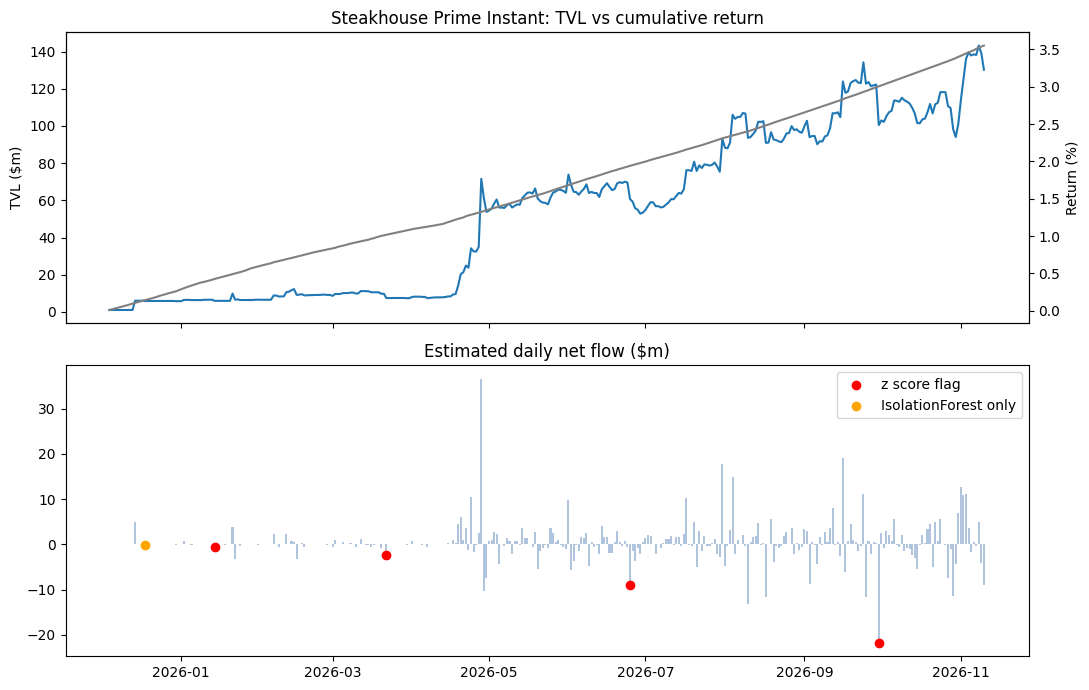

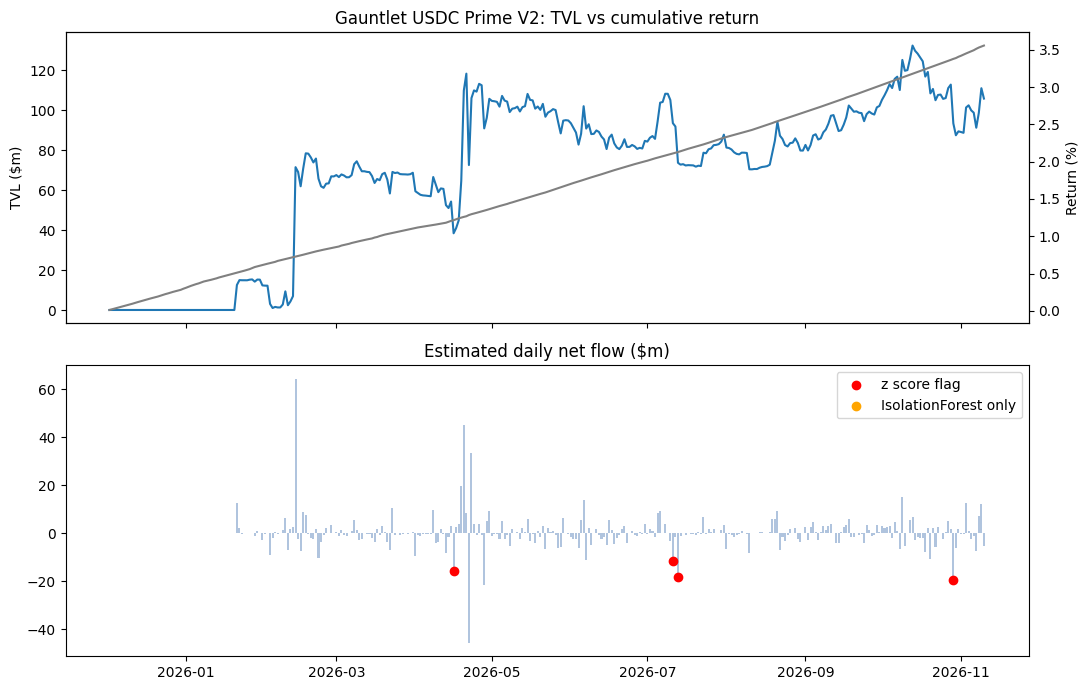

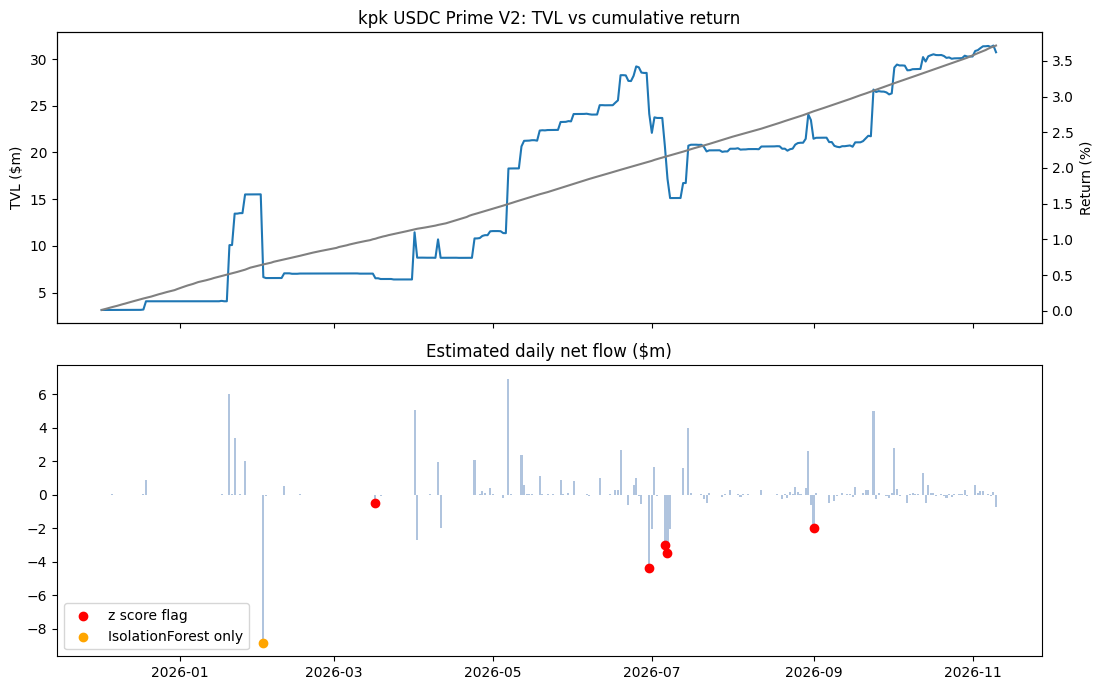

In [166]:
def plot(name, d):
    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    ax[0].plot(d.index, d["tvlUsd"] / 1e6, label="TVL ($m)")
    ax2 = ax[0].twinx()
    ax2.plot(d.index, d["cum_return"] * 100, color="gray", label="Cumulative return (%)")
    ax[0].set_title(f"{name}: TVL vs cumulative return")
    ax[0].set_ylabel("TVL ($m)"); ax2.set_ylabel("Return (%)")

    ax[1].bar(d.index, d["net_flow"] / 1e6, color="lightsteelblue")
    f = d[d["flag_z"]]; g = d[d["flag_if"] & ~d["flag_z"]]
    ax[1].scatter(f.index, f["net_flow"] / 1e6, color="red", label="z score flag", zorder=3)
    ax[1].scatter(g.index, g["net_flow"] / 1e6, color="orange", label="IsolationForest only", zorder=3)
    ax[1].set_title("Estimated daily net flow ($m)"); ax[1].legend()
    plt.tight_layout(); plt.show()

for name, d in out.items():
    plot(name, d)

In [167]:
for name, d in out.items():
    print(name)
    display(d[d["flag_z"] | d["flag_if"]][["tvlUsd", "net_flow", "z", "flag_z", "flag_if"]])

Steakhouse Prime Instant


,tvlUsd,net_flow,z,flag_z,flag_if
date,,,,,
2025-12-18,5845043,-1.514664e+05,NaN,False,True
2026-01-14,5925414,-5.998611e+05,-4.124493,True,False
2026-03-22,7403141,-2.367171e+06,-6.190602,True,False
2026-06-25,60667471,-8.880283e+06,-3.121171,True,False
2026-09-30,100484588,-2.178833e+07,-3.725030,True,False


Gauntlet USDC Prime V2


,tvlUsd,net_flow,z,flag_z,flag_if
date,,,,,
2026-04-16,38452871,-1.588119e+07,-4.337733,True,False
2026-07-11,93500885,-1.160229e+07,-3.073849,True,False
2026-07-13,73684645,-1.814494e+07,-4.573818,True,False
2026-10-29,93394055,-1.940976e+07,-4.127035,True,False


kpk USDC Prime V2


,tvlUsd,net_flow,z,flag_z,flag_if
date,,,,,
2026-02-02,6652707,-8.866548e+06,-2.318324,False,True
2026-03-17,6528626,-5.002449e+05,-79.444816,True,False
2026-06-30,24140620,-4.385741e+06,-7.008145,True,False
2026-07-06,20674450,-3.027150e+06,-3.024283,True,False
2026-07-07,17180164,-3.496291e+06,-3.415358,True,False
2026-09-01,21471559,-2.006781e+06,-3.817910,True,False


In [169]:
w3 = Web3(Web3.HTTPProvider("https://rpc.mevblocker.io"))
WITHDRAW = Web3.to_hex(Web3.keccak(text="Withdraw(address,address,address,uint256,uint256)"))
DEPOSIT = Web3.to_hex(Web3.keccak(text="Deposit(address,address,uint256,uint256)"))

def snapshot_window(pool_id, day):
    # DeFiLlama snapshots at about 23:00 UTC, so a row covers the previous snapshot to this one
    data = requests.get(f"https://yields.llama.fi/chart/{pool_id}", timeout=60).json()["data"]
    snaps = {pd.Timestamp(p["timestamp"]).tz_convert(None).normalize(): pd.Timestamp(p["timestamp"]) for p in data}
    day = pd.Timestamp(day)
    return int(snaps[day - pd.Timedelta(days=1)].timestamp()), int(snaps[day].timestamp())

def block_at(ts):
    # first block at or after a timestamp, by binary search
    latest = w3.eth.get_block("latest")
    lo = max(0, latest.number - (latest.timestamp - ts) // 12 - 20_000)
    hi = latest.number
    while lo < hi:
        mid = (lo + hi) // 2
        if w3.eth.get_block(mid).timestamp < ts:
            lo = mid + 1
        else:
            hi = mid
    return lo

def onchain_events(vault, start_ts, end_ts):
    a, b = block_at(start_ts), block_at(end_ts)
    rows = []
    for topic, kind in [(WITHDRAW, "withdraw"), (DEPOSIT, "deposit")]:
        for s in range(a, b, 5000):
            logs = w3.eth.get_logs({"address": Web3.to_checksum_address(vault), "topics": [topic],
                                    "fromBlock": s, "toBlock": min(s + 4999, b - 1)})
            for l in logs:
                rows.append({"kind": kind,
                             "usdc": int.from_bytes(bytes(l["data"])[:32], "big") / 1e6,
                             "owner": "0x" + bytes(l["topics"][-1])[-20:].hex(),
                             "tx": Web3.to_hex(l["transactionHash"])})
    return pd.DataFrame(rows, columns=["kind", "usdc", "owner", "tx"])

CHECKS = [
    ("Steakhouse Prime Instant", "2026-09-30"),
    ("Gauntlet USDC Prime V2", "2026-10-29"),
    ("Gauntlet USDC Prime V2", "2026-04-22"),
    ("kpk USDC Prime V2", "2026-02-02"),
    ("kpk USDC Prime V2", "2026-06-30"),
]

results = []
for name, day in CHECKS:
    t0, t1 = snapshot_window(VAULTS[name], day)
    ev = onchain_events(VAULT_ADDR[name], t0, t1)
    wd = ev[ev.kind == "withdraw"]
    onchain_net = ev.loc[ev.kind == "deposit", "usdc"].sum() - wd["usdc"].sum()
    model_net = out[name].loc[pd.Timestamp(day), "net_flow"]
    top = wd.sort_values("usdc", ascending=False).iloc[0]
    results.append({"vault": name, "day": day, "withdrawals": len(wd),
                    "deposits": (ev.kind == "deposit").sum(),
                    "onchain_net_usdc": round(onchain_net), "model_net_usdc": round(model_net),
                    "diff_%": round((model_net - onchain_net) / abs(onchain_net) * 100, 3),
                    "top_withdrawal_usdc": round(top["usdc"], 2), "top_owner": top["owner"], "top_tx": top["tx"]})

pd.set_option("display.max_colwidth", None)
pd.DataFrame(results)

,vault,day,withdrawals,deposits,onchain_net_usdc,model_net_usdc,diff_%,top_withdrawal_usdc,top_owner,top_tx
0,Steakhouse Prime Instant,2026-09-30,27,36,-21779837,-21788328,-0.039,26237393.31,0xbaed9839573d349e42dfbf23a8916e5ab9caf2e3,0x76adc316e3f2bd0526e6dbe5e42b7139655642388c1476e0439a88f6cc73edf3
1,Gauntlet USDC Prime V2,2026-10-29,51,10,-19404577,-19409757,-0.027,6602678.71,0x651fac183d2ac9753bec39f7530adf1b873f0314,0x4f9990439130560251a4c9a8d838182d7dc9b22803da76693525b053f0e1e153
2,Gauntlet USDC Prime V2,2026-04-22,34,65,-45706992,-45714217,-0.016,14998614.20,0x8092c20351cf4048b464df2144dc8a4dd49ce71d,0xfbfed3b742409f4034693961ed18760e9e436c123a2fa8532202f03c1664309c
3,kpk USDC Prime V2,2026-02-02,3,0,-8868789,-8866548,0.025,8021669.19,0x4f2083f5fbede34c2714affb3105539775f7fe64,0x3446f277e2dbd6942d7ee6c7a628e4ed7ca4bbf7b2b8d4411976468c05742c88
4,kpk USDC Prime V2,2026-06-30,2,4,-4384130,-4385741,-0.037,4920000.00,0x4f2083f5fbede34c2714affb3105539775f7fe64,0x819ffcbeeff33982291962902ccf10d4eb35844df2656357e61b79692a0d8b89


## Limits

1. TVL comes from DeFiLlama, not onchain data, and is measured in USD. Only USDC vaults are used so that price moves don't show up as flows.
2. apyBase is a smoothed annual figure, not the return earned each day, so it can't measure return volatility. The notebook doesn't report one.
3. The data is daily. A deposit and a withdrawal inside the same snapshot window cancel out. DeFiLlama snapshots at about 23:00 UTC, so onchain checks must use that window, not the calendar day.
4. Missing days are left blank, not filled in.
5. The z score can flag tiny moves when recent flows are close to zero. Gauntlet on 18 Jan flagged a $1,025 outflow from a $102k vault, and a minimum outflow filter of $250k removes it. kpk on 17 Mar shows a z of minus 79: the $500k outflow was real (about 7% of the vault), but the z value is inflated because the days before it were almost flat.
6. The opposite also happens: large inflows widen the baseline and hide the next outflow. Gauntlet's 45.71m outflow on 22 Apr, the largest in the sample, was missed by both methods for this reason.
7. There are no labelled anomalies, so precision can't be scored formally. Instead, five days were checked against Deposit and Withdraw events, and all five estimates matched within 0.1%. The 3 sigma threshold and 1% contamination are still assumptions.
8. Gauntlet's 92.89% max TVL drawdown comes from its first weeks, when TVL fell from 15.4m on 27 Jan to 1.1m on 4 Feb 2026. It has not been checked onchain.

## Next step

1. Build the baseline from outflow days only, or use a median based z score, so large inflows can't hide the next outflow. Fit IsolationForest on outflow days only for the same reason.
2. Run the web3.py event check over every day, not just the five checked here, and use convertToAssets() for the real share price instead of apyBase.